In [5]:
# Implementation1: This is a simple CUSUM with pre/post-change distributions already known

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from scipy.stats import norm

In [6]:
# Recursive CUSUM definition used 

class CUSUM:
    """
    Non-Bayesian CUSUM detector for i.i.d. observations.
    W_n = max(0, W_{n-1} + log(f1(X_n) / f0(X_n)))
    """
    
    def __init__(self, f0_pdf, f1_pdf, threshold):
        """
        Parameters
        f0_pdf : Pre-change density function f0(x).
        f1_pdf : Post-change density function f1(x).
        threshold : Detection threshold b.
        """
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.b = threshold

    def run(self, x):
        """
        Run CUSUM on a sequence of observations.
        
        Parameters
        x : array_like, shape (n_samples,) Observation sequence.
        
        Returns
        W : ndarray, shape (n_samples,) CUSUM statistic at each time n.
        tau : int or None Detection time (first n with W[n] >= b), or None if never.
        """
        x = np.asarray(x)
        W = np.zeros_like(x, dtype=float)
        S = np.zeros_like(x, dtype=float)   # cumulative log-likelihood sum

        tau = None

        for n in range(1, len(x)):
            llr = np.log(self.f1(x[n]) / self.f0(x[n]))     # log-likelihood ratio
            S[n] = S[n-1] + llr
            W[n] = max(0, W[n-1] + llr)                     # update CUSUM
            if tau is None and W[n] >= self.b:              # check threshold
                tau = n

        return W, S, tau



True change at n=100, detected at tau=128


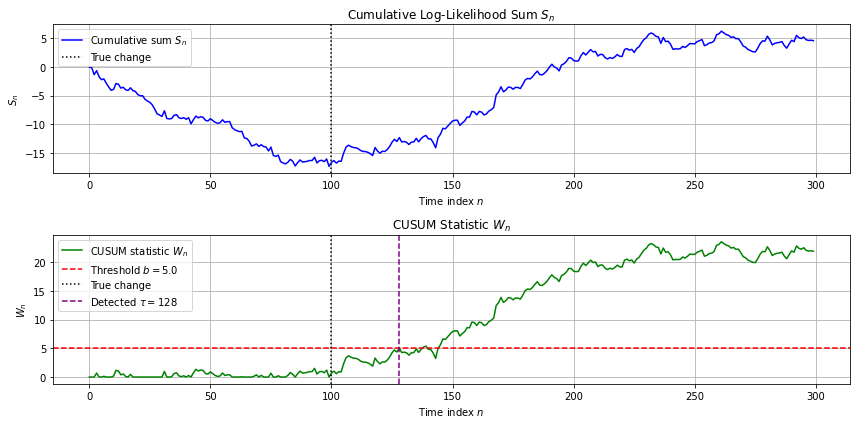

In [10]:

if __name__ == "__main__":
    # Simulate data: change from N(0,1) to N(0.5,1) at n=100
    np.random.seed(2)
    n_pre, n_post = 100, 200
    mu0, mu1, sigma = 0, 0.5, 1
    x = np.concatenate([
        np.random.normal(mu0, sigma, n_pre),
        np.random.normal(mu1, sigma, n_post)
    ])

    f0 = lambda x: norm.pdf(x, mu0, sigma)
    f1 = lambda x: norm.pdf(x, mu1, sigma)
    threshold = 5.0

    detector = CUSUM(f0, f1, threshold)
    W, S, tau = detector.run(x)

    print(f"True change at n={n_pre}, detected at tau={tau}")

    # Plot both CUSUM statistic W_n and raw cumulative sum S_n
    plt.figure(figsize=(12, 6))

    plt.subplot(2, 1, 1)
    plt.plot(S, label=r'Cumulative sum $S_n$', color='blue')
    plt.axvline(n_pre, color='k', linestyle=':', label='True change')
    plt.title('Cumulative Log-Likelihood Sum $S_n$')
    plt.xlabel('Time index $n$')
    plt.ylabel('$S_n$')
    plt.grid(True)
    plt.legend()

    plt.subplot(2, 1, 2)
    plt.plot(W, label=r'CUSUM statistic $W_n$', color='green')
    plt.axhline(threshold, color='red', linestyle='--', label=f'Threshold $b={threshold}$')
    plt.axvline(n_pre, color='k', linestyle=':', label='True change')
    if tau:
        plt.axvline(tau, color='purple', linestyle='--', label=f'Detected $\\tau={tau}$')
    plt.title('CUSUM Statistic $W_n$')
    plt.xlabel('Time index $n$')
    plt.ylabel('$W_n$')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()
